# EDA 13 · The relabelled February target on the w1 model (59 features) and the EDA model (20 features)

**Question.** Notebook 12 found that `train` (February) and `train_v2` (March) label the same renewal behaviour
differently, and that rebuilding the February target with the March rule fixes the under-prediction of the
per-cycle model. Does the same change help the two calendar-cutoff models that are actually candidates for w1:
the tuned XGBoost of `w1_xgboost_v2.ipynb` (M3v2, 59 features), and the 20-feature model of
the EDA (notebook 09)?

**Setting.** Whole cohort, fixed cutoff (2017-01-31 for February, 2017-02-28 for March), same split as w1
(`fit` / `stop` / `tune` on February, March as test). Each model is trained three times and nothing but the
February target changes:

| training target | February label switched to churn when ... |
|---|---|
| official | nothing (`is_churn` of `train`) |
| rules 1 + 2 | the only renewals in the 30-day window are plans longer than 31 days (rule 1), or the customer renews in the window and then cancels, ending at most 25 days after the original expiry (rule 2) |
| rules 1 + 2 + 3 | also every customer already paid beyond the next month at the cutoff (rule 3, exploratory) |

The window starts at the expiry when it falls in the label month, otherwise on the day after the cutoff
(notebook 12, section 5.1). The flags come from `cache/12_calendar.parquet`, built by notebook 12 from each
month's own transactions.

**How March labels are used.** Only to evaluate: every metric below is computed on the **official** March label.
Features, hyper-parameters, early stopping, calibration and thresholds use February only, with the training
target of each run. The rules themselves were found by auditing March labels (notebook 12).

In [1]:
import json
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
import xgboost as xgb
from xgboost import XGBClassifier

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
W1_DIR = EDA_DIR.parent / "w1"
sys.path.insert(0, str(EDA_DIR))
sys.path.insert(0, str(W1_DIR))
import _common as C
from src.models.constants import DEV_COHORT, TEST_COHORT
from src.models.feature_preparation.data import load_metadata, load_cohorts
from src.models.feature_preparation.environment import model_environment
from src.models.baselines.xgboost_v2 import _fit_v2, _complete_params, fit_isotonic_calibrator, apply_calibration

warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 40
pd.options.display.width = 220
TARGETS = ["official", "rules 1 + 2", "rules 1 + 2 + 3"]
EXP_ORDER = ["label month", "next month", "lapsed", "later", "no txn"]

## 1. The three February targets

`12_calendar.parquet` holds, for both cohorts, the 20 EDA features at the calendar cutoff and the two flags
(`long_only` for rule 1, `renew_cancel` for rule 2). Rule 3 is `expiry_month == "later"`.

In [2]:
cal_path = C.CACHE_DIR / "12_calendar.parquet"
assert cal_path.exists(), "run notebook 12 first: it builds cache/12_calendar.parquet"
cal = pl.read_parquet(cal_path)
yb, flip = pl.col("is_churn").cast(pl.Boolean), pl.col("long_only") | pl.col("renew_cancel")
cal = cal.with_columns(**{
    "official": pl.col("is_churn").cast(pl.Int8),
    "rules 1 + 2": (yb | flip).cast(pl.Int8),
    "rules 1 + 2 + 3": (yb | flip | (pl.col("expiry_month") == "later")).cast(pl.Int8)})

feb = cal.filter(pl.col("cohort") == "feb")
t = (cal.filter(pl.col("expiry_month") != "unknown").group_by("expiry_month").agg(
    n_feb=(pl.col("cohort") == "feb").sum(),
    **{f"Feb, {k}": pl.col(k).filter(pl.col("cohort") == "feb").mean() for k in TARGETS},
    **{"March, official": pl.col("is_churn").filter(pl.col("cohort") == "mar").mean()})
    .to_pandas().set_index("expiry_month").loc[EXP_ORDER])
t.loc["all"] = [feb.height, *[feb[k].mean() for k in TARGETS], cal.filter(pl.col("cohort") == "mar")["is_churn"].mean()]
print("labels switched to churn in February:",
      {k: int((feb[k] != feb["official"]).sum()) for k in TARGETS[1:]})
t

labels switched to churn in February: {'rules 1 + 2': 17353, 'rules 1 + 2 + 3': 21859}


,n_feb,"Feb, official","Feb, rules 1 + 2","Feb, rules 1 + 2 + 3","March, official"
expiry_month,,,,,
label month,"883,631.0000",0.0556,0.0746,0.0746,0.0729
next month,"85,485.0000",0.0400,0.0409,0.0409,0.0897
lapsed,"14,140.0000",0.5082,0.5201,0.5201,0.4973
later,"7,574.0000",0.4022,0.4051,1.0000,0.9043
no txn,"2,095.0000",0.3155,0.4864,0.4864,0.5468
all,"992,931.0000",0.0639,0.0814,0.0859,0.0899


Rules 1 + 2 switch 17,353 February labels and rule 3 another 4,506. The February churn rate goes from 6.4 % to
8.1 % and 8.6 %, against 9.0 % in March. Customers who expire in the label month and the prepaid group land on
their March rate. Customers who expire in the **next** month do not move (4 % in February, 9 % in March): no rule
is known for them.

## 2. Shared evaluation

For every run: thresholds are chosen on the February `tune` split with the training target of that run (max F1,
and max F2, the primary criterion of `w1_xgboost_v2`), then applied unchanged to March.

In [3]:
def pick(y, p, beta=1):
    # threshold that maximises F-beta, and the F-beta reached
    pr, rc, thr = precision_recall_curve(y, p)
    f = (1 + beta**2) * pr * rc / np.clip(beta**2 * pr + rc, 1e-12, None)
    i = np.argmax(f[:-1])
    return thr[i], f[i]

def prf(y, yhat):
    tp = (yhat & (y == 1)).sum()
    pr, rc = tp / max(yhat.sum(), 1), tp / y.sum()
    return pr, rc, 2 * pr * rc / max(pr + rc, 1e-12), 5 * pr * rc / max(4 * pr + rc, 1e-12)

RESULTS, PRED, FLAG = [], {}, {}
def record(model, target, feb_rate, best_iter, y_tune, p_tune, y_mar, p_mar, rank_mar):
    # p_*: probabilities used for the threshold; rank_mar: raw scores used for AUC / AP
    PRED[(model, target)] = p_mar
    for crit, beta in (("F1", 1), ("F2", 2)):
        thr, _ = pick(y_tune, p_tune, beta)
        yhat = p_mar >= thr
        pr, rc, f1, f2 = prf(y_mar, yhat)
        if crit == "F1":
            FLAG[(model, target)] = yhat
        RESULTS.append({"model": model, "training target": target, "threshold by": crit, "trees": best_iter,
                        "Feb churn rate": feb_rate, "March mean p": p_mar.mean(), "March churn rate": y_mar.mean(),
                        "AUC": roc_auc_score(y_mar, rank_mar), "AP": average_precision_score(y_mar, rank_mar),
                        "threshold": thr, "precision": pr, "recall": rc, "F1": f1, "F2": f2,
                        "F1, best March threshold": pick(y_mar, rank_mar)[1],
                        "FN": int((~yhat & (y_mar == 1)).sum()), "FP": int((yhat & (y_mar == 0)).sum())})

## 3. EDA model: 20 features

Same features and XGBoost settings as notebook 09 and notebook 12, section 5.1 (`expiry_month` instead of
`days_to_expire`, no hyper-parameter search, no calibration step: the threshold is taken on the raw probability).

In [4]:
M20 = "EDA, 20 features"
CAT = ["state", "expiry_month", "plan_band", "price_level", "price_type", "pm_group", "via", "profile_state", "age_band"]
NUM = ["payer_days", "n_payments", "n_lapses", "total_lapse_days", "has_logs", "days_since_last_log", "longest_gap",
       "active_days_30", "secs_30", "bd", "tenure_days"]
F20 = CAT + NUM
PARAMS20 = dict(n_estimators=4000, learning_rate=0.05, max_depth=6, min_child_weight=5, subsample=0.8,
                colsample_bytree=0.8, reg_lambda=1.0, tree_method="hist", eval_metric="aucpr",
                early_stopping_rounds=150, enable_categorical=True, max_cat_to_onehot=1, n_jobs=16, random_state=C.SEED)
LEVELS = {c: sorted(v for v in feb[c].unique().to_list() if v is not None) for c in CAT}

def to_X20(df):
    p = df.select(F20).to_pandas()
    for c in CAT:
        codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)
        codes[codes < 0] = np.nan
        p[c] = codes
    return p.astype(float)

fit20, stop20, tune20, mar20 = (cal.filter(pl.col("split") == s) for s in ("fit", "stop", "tune", "march"))
Xf, Xs, Xt, Xm = map(to_X20, (fit20, stop20, tune20, mar20))
y_mar20 = mar20["is_churn"].to_numpy()
for target in TARGETS:
    m = XGBClassifier(**PARAMS20, feature_types=["c" if c in CAT else "q" for c in F20])
    m.fit(Xf, fit20[target].to_numpy(), eval_set=[(Xs, stop20[target].to_numpy())], verbose=False)
    p_mar = m.predict_proba(Xm)[:, 1]
    record(M20, target, feb[target].mean(), m.best_iteration, tune20[target].to_numpy(), m.predict_proba(Xt)[:, 1],
           y_mar20, p_mar, p_mar)
print({s: x.height for s, x in zip(("fit", "stop", "tune", "march"), (fit20, stop20, tune20, mar20))})

{'fit': 744699, 'stop': 124117, 'tune': 124115, 'march': 970960}


## 4. w1 model: 59 features (M3v2)

The 59 features of the saved M3v2 model (`artifacts/sherlock_w1_xgb_v2/models/M3v2.joblib`), the split of
`artifacts/sherlock_w1/split_indices.npz` and the hyper-parameters that `w1_xgboost_v2.ipynb` selected with 80
Optuna trials (`best_params.json`). The local `export-tabular-v5` is the older 108-column export: it holds 55 of
the 59 features, and the other four (`trend_songs`, `trend_secs`, `trend_ratio100`, `trend_ratio25`) are rebuilt
from its columns with the formulas of `w1/src/data_processing/user_logs/monthly.py`. As a check, the saved model
is scored on March with these columns and must reproduce the AP reported in `w1_xgboost_v2.ipynb` (0.596). The
search is **not** repeated for the relabelled targets: the parameters were tuned on the official label, which if
anything favours the official run. As in that notebook: fit on `fit`, early stopping on `stop` (100 rounds),
isotonic calibration on `tune`, thresholds on the calibrated `tune` probabilities. AUC and AP are computed on the
raw scores (isotonic calibration creates ties).

In [5]:
M59 = "w1 M3v2, 59 features"
INPUT_DIR = W1_DIR / "export-tabular-v5"
META, EXPORT_FEATURES, CATEGORICAL, _ = load_metadata(INPUT_DIR)
cohort_df, y_all, COHORT = load_cohorts(INPUT_DIR, META, EXPORT_FEATURES, DEV_COHORT, TEST_COHORT)
cohort_df = cohort_df.assign(      # the four trend features of the 59-feature export (monthly.py, _add_trend_features)
    trend_songs=cohort_df["last_sum_total_songs"] / (cohort_df["last_second_sum_total_songs"] + 1),
    trend_secs=cohort_df["sum_last_month_total_secs"] / (cohort_df["sum_last_second_month_total_secs"] + 1),
    trend_ratio100=cohort_df["last_ratio_100"] - cohort_df["last_second_ratio_100"],
    trend_ratio25=cohort_df["last_ratio_25"] - cohort_df["last_second_ratio_25"])
saved = joblib.load(W1_DIR / "artifacts/sherlock_w1_xgb_v2/models/M3v2.joblib")
FEATURES = [str(f) for f in saved.feature_names_in_]
assert len(FEATURES) == 59 and set(FEATURES) <= set(cohort_df.columns) and set(CATEGORICAL) <= set(FEATURES)
npz = np.load(W1_DIR / "artifacts/sherlock_w1/split_indices.npz")
SPLIT = {k: npz[k] for k in ("fit", "stop", "tune", "test")}

# align the targets of section 1 to the rows of the w1 export
lab = cal.select("msno", "cohort", "expiry_month", *TARGETS).to_pandas()
lab["cohort"] = lab["cohort"].map({"feb": DEV_COHORT, "mar": TEST_COHORT})
lab = cohort_df[["msno", "cohort"]].astype({"cohort": str}).merge(lab, on=["msno", "cohort"], how="left", validate="one_to_one")
assert lab["official"].notna().all() and (lab["official"].to_numpy() == y_all).all(), "w1 export and EDA cohort differ"
Y = {k: lab[k].to_numpy().astype(np.int32) for k in TARGETS}
split_names = cal.select("msno", "cohort", "split").to_pandas()
assert all((lab.iloc[SPLIT[a]][["msno"]].merge(split_names[split_names["split"] == b], on="msno").shape[0] == len(SPLIT[a]))
           for a, b in (("fit", "fit"), ("stop", "stop"), ("tune", "tune"))), "w1 split and EDA split differ"

vocab = {c: sorted(int(v) for v in pd.unique(cohort_df[c].iloc[SPLIT["fit"]].dropna())) for c in CATEGORICAL}
def tree_frame(rows):
    # same encoding as w1_xgboost_v2: categorical levels of `fit` as integer codes, -1 when unseen
    frame = cohort_df.iloc[np.asarray(rows)][FEATURES].copy()
    for col in frame.select_dtypes(include="category").columns:
        frame[col] = np.asarray(frame[col])
    for c in CATEGORICAL:
        codes = {level: i for i, level in enumerate(vocab[c])}
        frame[c] = frame[c].map(codes).fillna(-1).astype("int64")
    return frame

X59 = {part: tree_frame(SPLIT[part]) for part in SPLIT}
DEVICE, ENV = model_environment(C.SEED)
params59 = _complete_params(json.loads((W1_DIR / "artifacts/sherlock_w1_xgb_v2/best_params.json").read_text()))
y_mar59 = y_all[SPLIT["test"]]
p_saved = saved.get_booster().predict(xgb.DMatrix(X59["test"].to_numpy(dtype=np.float32), feature_names=FEATURES))
print(f"saved M3v2 scored on March with these 59 columns: AP {average_precision_score(y_mar59, p_saved):.4f}"
      " (w1_xgboost_v2.ipynb: 0.5960)")
for target in TARGETS:
    y = Y[target]
    m = _fit_v2(params59, X59["fit"], y[SPLIT["fit"]], X59["stop"], y[SPLIT["stop"]],
                device=DEVICE, max_rounds=3000, early_stop=100, log_period=0, seed=C.SEED)
    raw_tune, raw_mar = m.predict_proba(X59["tune"])[:, 1], m.predict_proba(X59["test"])[:, 1]
    iso = fit_isotonic_calibrator(raw_tune, y[SPLIT["tune"]])
    record(M59, target, y[COHORT == DEV_COHORT].mean(), int(m.best_iteration), y[SPLIT["tune"]],
           apply_calibration(iso, raw_tune), y_mar59, apply_calibration(iso, raw_mar), raw_mar)
print("device:", DEVICE, "| features:", len(FEATURES))

train_feb rows:   992,931 | label month: 2017-02 | churn rate: 0.0639
test      rows:   970,960 | label month: 2017-03 | churn rate: 0.0899


labelled cohorts: (1963891, 112) | users in both labelled months: 881701


saved M3v2 scored on March with these 59 columns: AP 0.5958 (w1_xgboost_v2.ipynb: 0.5960)


sh: línea 1: nvidia-smi: orden no encontrada


device: cuda | features: 59


## 5. Results on March (official label)

First table: threshold = max F1 on February `tune`. Second table: both threshold criteria.

In [6]:
res = pd.DataFrame(RESULTS)
res.to_csv(C.CACHE_DIR / "13_results.csv", index=False)
main = res[res["threshold by"] == "F1"].set_index(["model", "training target"])
display(main[["trees", "Feb churn rate", "March mean p", "March churn rate", "AUC", "AP", "threshold", "precision", "recall",
              "F1", "F1, best March threshold", "FN", "FP"]])
res.set_index(["model", "training target", "threshold by"])[["threshold", "precision", "recall", "F1", "F2", "FN", "FP"]]

trees  Feb churn rate  March mean p  March churn rate    AUC     AP  threshold  precision  recall     F1  F1, best March threshold     FN     FP
model                training target                                                                                                                                                  
EDA, 20 features     official           342          0.0639        0.0637            0.0899 0.8689 0.6009     0.2444     0.6429  0.5357 0.5844                    0.5853  40550  25987
                     rules 1 + 2        314          0.0814        0.0812            0.0899 0.8624 0.6273     0.3091     0.6567  0.5392 0.5922                    0.5923  40242  24620
                     rules 1 + 2 + 3    338          0.0859        0.0866            0.0899 0.8886 0.6609     0.3706     0.7125  0.5618 0.6282                    0.6298  38265  19802
w1 M3v2, 59 features official           673          0.0639        0.0660            0.0899 0.8668 0.5962     0.2879     0.6474  0.5224 0.5782                    0.5805  41711  24843
                     rules 1 + 2       1107          0.0814        0.0838            0.0899 0.8568 0.6217     0.3258     0.6393  0.5400 0.5855                    0.5861  40170  26610
                     rules 1 + 2 + 3   1101          0.0859        0.0932            0.0899 0.8839 0.6030     0.3000     0.6307  0.5912 0.6103                    0.6107  35704  30230

threshold  precision  recall     F1     F2     FN     FP
model                training target threshold by                                                          
EDA, 20 features     official        F1               0.2444     0.6429  0.5357 0.5844 0.5542  40550  25987
                                     F2               0.1303     0.5024  0.6342 0.5607 0.6026  31945  54857
                     rules 1 + 2     F1               0.3091     0.6567  0.5392 0.5922 0.5592  40242  24620
                                     F2               0.1284     0.4497  0.6678 0.5374 0.6087  29011  71374
                     rules 1 + 2 + 3 F1               0.3706     0.7125  0.5618 0.6282 0.5866  38265  19802
                                     F2               0.1355     0.4806  0.7124 0.5739 0.6497  25117  67248
w1 M3v2, 59 features official        F1               0.2879     0.6474  0.5224 0.5782 0.5434  41711  24843
                                     F2               0.1281     0.4741  0.6501 0.5483 0.6051  30559  62976
                     rules 1 + 2     F1               0.3258     0.6393  0.5400 0.5855 0.5573  40170  26610
                                     F2               0.1300     0.4479  0.6667 0.5358 0.6073  29111  71768
                     rules 1 + 2 + 3 F1               0.3000     0.6307  0.5912 0.6103 0.5987  35704  30230
                                     F2               0.1569     0.4613  0.7150 0.5608 0.6442  24885  72912

In [7]:
# paired bootstrap of the March F1 difference against the official target (threshold = max F1 on tune)
rng = np.random.default_rng(C.SEED)
rows = []
for model, y in ((M20, y_mar20), (M59, y_mar59)):
    for target in TARGETS[1:]:
        d = []
        for _ in range(300):
            i = rng.integers(0, len(y), len(y))
            d.append(prf(y[i], FLAG[(model, target)][i])[2] - prf(y[i], FLAG[(model, "official")][i])[2])
        rows.append({"model": model, "training target": target, "d_F1 vs official": np.mean(d),
                     "ci_95_low": np.percentile(d, 2.5), "ci_95_high": np.percentile(d, 97.5)})
pd.DataFrame(rows).set_index(["model", "training target"])

d_F1 vs official  ci_95_low  ci_95_high
model                training target                                         
EDA, 20 features     rules 1 + 2                0.0078     0.0068      0.0088
                     rules 1 + 2 + 3            0.0438     0.0421      0.0456
w1 M3v2, 59 features rules 1 + 2                0.0073     0.0062      0.0085
                     rules 1 + 2 + 3            0.0321     0.0305      0.0339

## 6. Where each target is calibrated

Mean predicted probability on March against the real March churn rate, by position of the expiry at the cutoff.

In [8]:
exp20, exp59 = mar20["expiry_month"].to_numpy(), lab["expiry_month"].to_numpy()[SPLIT["test"]]
def calib(model, y, exp):
    d = pd.DataFrame({"expiry_month": exp, "March churn rate": y, **{f"mean p, {k}": PRED[(model, k)] for k in TARGETS}})
    g = d.groupby("expiry_month").agg(n=("March churn rate", "size"), **{c: (c, "mean") for c in d.columns[1:]})
    return g.loc[EXP_ORDER]
cal_seg = pd.concat({M20: calib(M20, y_mar20, exp20), M59: calib(M59, y_mar59, exp59)})
cal_seg

n  March churn rate  mean p, official  mean p, rules 1 + 2  mean p, rules 1 + 2 + 3
                     expiry_month                                                                                          
EDA, 20 features     label month   865793            0.0729            0.0546               0.0728                   0.0727
                     next month     77433            0.0897            0.0426               0.0433                   0.0432
                     lapsed         16993            0.4973            0.4540               0.4842                   0.4822
                     later           8214            0.9043            0.3308               0.3342                   0.9990
                     no txn          2524            0.5468            0.3394               0.5713                   0.5718
w1 M3v2, 59 features label month   865793            0.0729            0.0576               0.0763                   0.0762
                     next month     77433            0.0897            0.0436               0.0450                   0.0933
                     lapsed         16993            0.4973            0.4293               0.4504                   0.4516
                     later           8214            0.9043            0.3252               0.3272                   0.9913
                     no txn          2524            0.5468            0.3438               0.5717                   0.5706

In [9]:
# rule 3 inside the 59-feature model: it has days_to_expire as a number, not expiry_month
dte = cohort_df["days_to_expire"].to_numpy()
def dte_table(rows, y, p=None):
    d = pd.DataFrame({"expiry_month": lab["expiry_month"].to_numpy()[rows], "days_to_expire": dte[rows], "churn": y})
    if p is not None:
        d["mean p, rules 1 + 2"], d["mean p, rules 1 + 2 + 3"] = p
    d = d[d["expiry_month"].isin(["next month", "later"])]
    d["days_to_expire band"] = pd.cut(d["days_to_expire"], [0, 31, 56, 59, 61, 10_000], labels=["<= 31", "32-56", "57-59", "60-61", ">= 62"])
    return d.groupby(["expiry_month", "days_to_expire band"], observed=True).agg(
        n=("churn", "size"), **{c: (c, "mean") for c in d.columns if c == "churn" or c.startswith("mean p")})
dev_rows = np.flatnonzero(COHORT == DEV_COHORT)
print("February (training target rules 1 + 2 + 3)")
display(dte_table(dev_rows, Y["rules 1 + 2 + 3"][dev_rows]))
print("March (official label)")
dte_table(SPLIT["test"], y_mar59, (PRED[(M59, "rules 1 + 2")], PRED[(M59, "rules 1 + 2 + 3")]))

February (training target rules 1 + 2 + 3)


n  churn
expiry_month days_to_expire band              
later        60-61                  623 1.0000
             >= 62                 6951 1.0000
next month   <= 31                15952 0.0532
             32-56                69159 0.0367
             57-59                  300 0.2367

March (official label)


n  churn  mean p, rules 1 + 2  mean p, rules 1 + 2 + 3
expiry_month days_to_expire band                                                            
later        32-56                  168 1.0000               0.6141                   0.5969
             57-59                   11 1.0000               0.7142                   0.6871
             60-61                    6 1.0000               0.8476                   1.0000
             >= 62                 8029 0.9021               0.3203                   1.0000
next month   32-56                65674 0.0940               0.0449                   0.0444
             57-59                 7799 0.0701               0.0422                   0.0449
             60-61                 3960 0.0573               0.0515                   1.0000

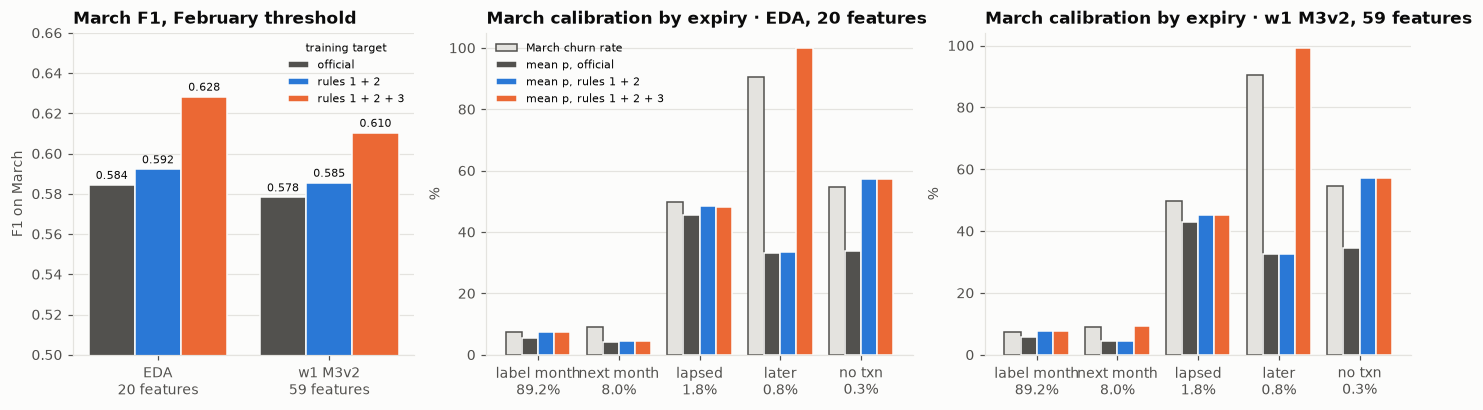

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.25, 1.25]})
colors = {"official": C.COLORS["base"], "rules 1 + 2": C.COLORS["stay"], "rules 1 + 2 + 3": C.COLORS["churn"]}
x, w = np.arange(2), 0.27
for j, target in enumerate(TARGETS):
    for ax, col in ((axes[0], "F1"),):
        vals = [main.loc[(m, target), col] for m in (M20, M59)]
        ax.bar(x + (j - 1) * w, vals, w, color=colors[target], label=target, edgecolor=C.COLORS["surface"])
        for xi, v in zip(x + (j - 1) * w, vals):
            ax.text(xi, v + 0.003, f"{v:.3f}", ha="center", fontsize=7, color=C.COLORS["text"])
axes[0].set_xticks(x, ["EDA\n20 features", "w1 M3v2\n59 features"]); axes[0].set_ylim(0.5, 0.66)
axes[0].set_ylabel("F1 on March"); axes[0].set_title("March F1, February threshold", loc="left")
axes[0].legend(frameon=False, fontsize=7, title="training target", title_fontsize=7)
xs = np.arange(len(EXP_ORDER))
for ax, model in zip(axes[1:], (M20, M59)):
    c = cal_seg.loc[model]
    ax.bar(xs - 1.5 * 0.2, c["March churn rate"] * 100, 0.2, color=C.COLORS["grid"], edgecolor=C.COLORS["muted"], label="March churn rate")
    for j, target in enumerate(TARGETS):
        ax.bar(xs + (j - 0.5) * 0.2, c[f"mean p, {target}"] * 100, 0.2, color=colors[target], label=f"mean p, {target}",
               edgecolor=C.COLORS["surface"])
    ax.set_xticks(xs, [f"{e}\n{n / c['n'].sum():.1%}" for e, n in zip(EXP_ORDER, c["n"])])
    ax.set_ylabel("%"); ax.set_title(f"March calibration by expiry · {model}", loc="left")
axes[1].legend(frameon=False, fontsize=7)
fig.tight_layout(); C.save_fig(fig, "13_relabelled_models"); plt.show()

## 7. Conclusion

**The relabelled February target improves both models on the official March label, and the two models respond
in the same way.** March metrics, threshold = max F1 on February `tune`:

| model | training target | Feb churn rate | March mean p (real 9.0 %) | AP | precision | recall | F1 | d F1 (95 % CI) |
|---|---|---|---|---|---|---|---|---|
| EDA, 20 features | official | 6.4 % | 6.4 % | 0.601 | 0.643 | 0.536 | 0.584 | |
| | rules 1 + 2 | 8.1 % | 8.1 % | 0.627 | 0.657 | 0.539 | 0.592 | +0.008 (+0.007, +0.009) |
| | rules 1 + 2 + 3 | 8.6 % | 8.7 % | 0.661 | 0.713 | 0.562 | **0.628** | +0.044 (+0.042, +0.046) |
| w1 M3v2, 59 features | official | 6.4 % | 6.6 % | 0.596 | 0.647 | 0.522 | 0.578 | |
| | rules 1 + 2 | 8.1 % | 8.4 % | 0.622 | 0.639 | 0.540 | 0.586 | +0.007 (+0.006, +0.009) |
| | rules 1 + 2 + 3 | 8.6 % | 9.3 % | 0.603 | 0.631 | 0.591 | **0.610** | +0.032 (+0.031, +0.034) |

- **Rules 1 + 2** give the same small gain to both models: F1 +0.007 / +0.008 and AP +0.026. They calibrate the
  89 % of customers who expire in the label month (7.3 % predicted, 7.3 % real with 20 features; 7.6 % with 59),
  but the customers out of scope hold 28 % of the March churners and stay mislabelled.
- **Rule 3** gives most of the F1 gain in both models (+0.044 and +0.032 in total): the 8,214 prepaid customers
  go from 33 % predicted to 99–100 % (real 90 %).
- **The 20-feature model is ahead under every target**, and the distance grows with the relabelling: F1 0.584 vs
  0.578 with the official label, 0.628 vs 0.610 with rules 1 + 2 + 3; AP 0.661 vs 0.603.
- **Rule 3 does not transfer cleanly through `days_to_expire`** (section 6). In February "paid beyond the next
  month" means `days_to_expire >= 60`; in March it means `>= 62`, because the next month has 30 days instead of 31.
  The 59-feature model learns the February number and gives p = 1.00 to 3,960 March customers who expire on
  April 29–30 and churn 5.7 %: about 3,700 false positives. This is why its AP falls from 0.622 to 0.603 with
  rule 3 while its F1 still rises. The 20-feature model uses `expiry_month`, which is defined by calendar month,
  and does not have the problem (next month: 4.3 % predicted with and without rule 3).
- With the relabelled targets the February threshold is within 0.002 F1 of the best March threshold in both
  models. With the official label the 59-feature model loses 0.002 and the 20-feature model 0.001, so in this
  calendar setting the threshold was never the main problem: the ranking was.
- Customers who expire in the next month are still under-predicted by both models (4.3–4.5 % against 9.0 %). No
  rule is known for them.
- The F2 threshold (primary criterion of `w1_xgboost_v2`) moves less with rules 1 + 2 (F2 +0.002 / +0.006) and
  clearly with rule 3 (0.605 → 0.644 with 59 features, 0.603 → 0.650 with 20).

**Caveats.**
- The rules were found by auditing March labels (notebook 12), so the gains are not blind estimates. Rule 3 is
  the weakest: it was identified on one group of 7,574 / 8,214 customers and is 90 % pure in March, not 97 %.
- The hyper-parameters of the 59-feature model were tuned on the official label and are reused for the
  relabelled targets; the 20-feature model has no search at all. A search per target could change the numbers by
  a few thousandths, not the ordering.
- The 59 features come from the local 108-column export plus four trend features rebuilt here. The saved M3v2
  model scored on them reproduces its reported March AP (0.596), so the reconstruction is faithful.

**Recommendation.**
1. Train w1 on the relabelled February target (rules 1 + 2 + 3) whenever the model is evaluated on `train_v2`;
   keep the official February label only for February reporting.
2. If rule 3 is used with the 59 features, replace `days_to_expire` by a calendar-month encoding (`expiry_month`),
   or the rule turns into false positives in months of another length.
3. Prefer the 20-feature set: it is better under every target and it is the one that benefits most from the
   consistent label.

In [11]:
C.write_decisions("13", "Relabelled February target on the w1 (59 features) and EDA (20 features) models", [
    {"finding": "Trained on February relabelled with rules 1 + 2 and evaluated on the official March label, both calendar models gain the same: F1 0.584 -> 0.592 (20 features) and 0.578 -> 0.586 (w1 M3v2, 59 features), AP +0.026 in both; customers expiring in the label month become calibrated (7.3 % predicted vs 7.3 % real)",
     "decision": "Use the relabelled February target for w1 models evaluated on train_v2; official February label only for February reporting", "kind": "transformation"},
    {"finding": "Adding rule 3 (prepaid beyond the next month = churn) gives most of the gain: F1 0.628 / AP 0.661 with 20 features, F1 0.610 / AP 0.603 with 59 features (d F1 +0.044 and +0.032, bootstrap CIs exclude 0)",
     "decision": "Train with rules 1 + 2 + 3; rule 3 stays flagged as exploratory (found on one group, 90 % pure in March) until the train_v2 definition is confirmed", "kind": "open"},
    {"finding": "With rule 3 the 59-feature model learns days_to_expire >= 60 from February; in March the boundary is 62, so 3,960 customers expiring on April 29-30 (5.7 % churn) get p = 1.00 (~3,700 false positives) and AP falls 0.622 -> 0.603. The 20-feature model uses expiry_month and is not affected",
     "decision": "Encode the expiry by calendar month (expiry_month) instead of numeric days_to_expire in any calendar-cutoff model trained with rule 3", "kind": "transformation"},
    {"finding": "The 20-feature model beats the tuned 59-feature model under every training target (F1 0.584 vs 0.578, 0.592 vs 0.586, 0.628 vs 0.610)",
     "decision": "Keep the 20-feature set as the w1 feature table (confirms notebook 09)", "kind": "no action"},
    {"finding": "Customers expiring in the next month stay under-predicted in both models (4.3-4.5 % vs 9.0 %)",
     "decision": "No rule identified; report this segment separately", "kind": "open"},
])

,finding,decision,kind
0,Trained on February relabelled with rules 1 + ...,Use the relabelled February target for w1 mode...,transformation
1,Adding rule 3 (prepaid beyond the next month =...,Train with rules 1 + 2 + 3; rule 3 stays flagg...,open
2,With rule 3 the 59-feature model learns days_t...,Encode the expiry by calendar month (expiry_mo...,transformation
3,The 20-feature model beats the tuned 59-featur...,Keep the 20-feature set as the w1 feature tabl...,no action
4,Customers expiring in the next month stay unde...,No rule identified; report this segment separa...,open
